# Cora centroid hypergraph — HMRW sweep over `q_edge`

Loads **`data/cora_centroid/cora_centroid.pickle`** (hypergraph + labels; produced by `cora_centroid_hypergraph.ipynb`) and runs **HMRW** (`src.utils.hmrw_embeddings`) with most parameters fixed, varying only **`q_edge`**. No Cora source folder is needed on read.

Evaluation: **stratified 5-fold CV** with logistic regression on the learned embeddings (same pattern as `hmrw_pedge_qedge_only.ipynb`).

In [6]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hypergraphx import Hypergraph
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

from src.utils import hmrw_embeddings

In [7]:
def evaluate_embeddings(X, y, seed=42, n_splits=5):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    clf = LogisticRegression(max_iter=3000)
    scores = cross_validate(
        clf,
        X,
        y,
        cv=cv,
        scoring={"micro_f1": "f1_micro", "macro_f1": "f1_macro"},
        n_jobs=-1,
        return_train_score=False,
    )
    return float(np.mean(scores["test_micro_f1"])), float(np.mean(scores["test_macro_f1"]))

In [8]:
data_dir = Path("data") / "cora_centroid"
with open(data_dir / "cora_centroid.pickle", "rb") as f:
    bundle = pickle.load(f)
edge_list = bundle["edge_list"]
y = np.asarray(bundle["labels"], dtype=int)
H = Hypergraph(edge_list)
assert len(y) == len(edge_list), (len(y), len(edge_list))

print(f"Nodes: {len(sorted(H.get_nodes()))}, distinct hyperedges: {len(H.get_edges())}, labels: {y.shape}")

Nodes: 2708, distinct hyperedges: 2590, labels: (2708,)


In [ ]:
# Fixed HMRW / Skip-gram settings (edit here)
fixed_params = dict(
    p=1.0,
    q=1.0,
    p_edge=1.0,
    num_walks=10,
    walk_length=40,
    window=10,
    dim=128,
    workers=1,
)

q_edge_values = [0.25, 0.5, 1.0, 2.0, 4.0]
n_repeats = 5
base_seed = 42

In [ ]:
rows = []
for q_edge in q_edge_values:
    print(q_edge)
    micro_runs = []
    macro_runs = []
    for rep in range(n_repeats):
        seed = base_seed + rep
        X = hmrw_embeddings(H, q_edge=q_edge, seed=seed, **fixed_params)
        micro, macro = evaluate_embeddings(X, y, seed=seed)
        micro_runs.append(micro)
        macro_runs.append(macro)
    rows.append(
        {
            "q_edge": q_edge,
            "micro_f1_mean": float(np.mean(micro_runs)),
            "micro_f1_std": float(np.std(micro_runs)),
            "macro_f1_mean": float(np.mean(macro_runs)),
            "macro_f1_std": float(np.std(macro_runs)),
        }
    )

results = pd.DataFrame(rows).sort_values("macro_f1_mean", ascending=False)

# Save results
results_dir = Path("results") / "cora"
results_dir.mkdir(parents=True, exist_ok=True)
results_path = results_dir / "hmrw_qedge_sweep.csv"
results.to_csv(results_path, index=False)
print(f"Saved results to: {results_path}")

results

0.25


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


0.5


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


1.0


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


... (2 outputs left out)

4.0


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Saved results to: results/cora/hmrw_qedge_sweep.csv


,q_edge,micro_f1_mean,micro_f1_std,macro_f1_mean,macro_f1_std
3,2.00,0.816468,0.005175,0.808381,0.005214
4,4.00,0.812110,0.008576,0.804266,0.009287
0,0.25,0.810558,0.005947,0.803363,0.005396
1,0.50,0.811671,0.005362,0.802481,0.004838
2,1.00,0.810410,0.004977,0.802007,0.004088


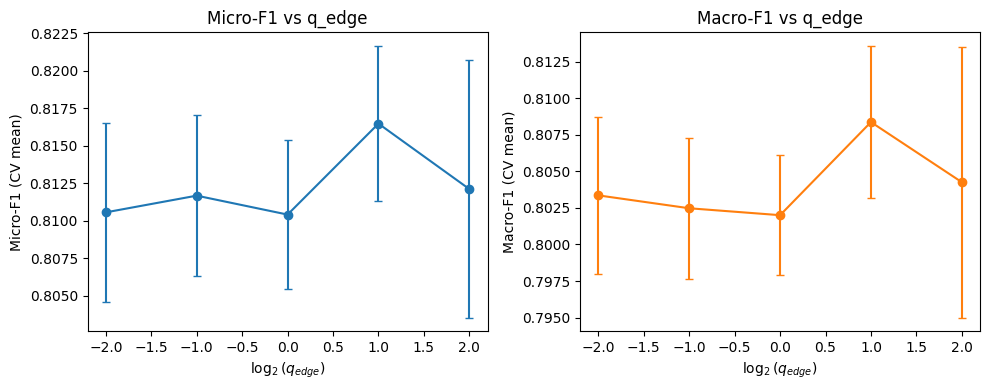

In [ ]:
curve = results.sort_values("q_edge")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
x = np.log2(curve["q_edge"].to_numpy())
axes[0].errorbar(x, curve["micro_f1_mean"], yerr=curve["micro_f1_std"], marker="o", capsize=3)
axes[0].set_xlabel(r"$\log_2(q_{edge})$")
axes[0].set_ylabel("Micro-F1 (CV mean)")
axes[0].set_title("Micro-F1 vs q_edge")
axes[1].errorbar(x, curve["macro_f1_mean"], yerr=curve["macro_f1_std"], marker="o", capsize=3, color="tab:orange")
axes[1].set_xlabel(r"$\log_2(q_{edge})$")
axes[1].set_ylabel("Macro-F1 (CV mean)")
axes[1].set_title("Macro-F1 vs q_edge")
fig.tight_layout()
plt.show()

## Additional sweep: vary `p_edge` (keep existing cells unchanged)

This block runs a separate `p_edge` sweep using the currently loaded `H` and `y`, saves a CSV to `results/cora`, and plots Micro/Macro-F1 vs `p_edge`.

In [17]:
# Separate p_edge sweep (additive; does not modify previous results)
pedge_fixed_params = dict(
    p=1.0,
    q=1.0,
    q_edge=1.0,
    num_walks=10,
    walk_length=40,
    window=10,
    dim=128,
    workers=1,
)

p_edge_values = [0.25, 0.5, 1.0, 2.0, 4.0]
n_repeats = 5
base_seed = 42

rows_pedge = []
for p_edge in p_edge_values:
    print(p_edge)
    micro_runs, macro_runs = [], []
    for rep in range(n_repeats):
        seed = base_seed + rep
        X = hmrw_embeddings(H, p_edge=p_edge, seed=seed, **pedge_fixed_params)
        micro, macro = evaluate_embeddings(X, y, seed=seed)
        micro_runs.append(micro)
        macro_runs.append(macro)
    rows_pedge.append(
        {
            "p_edge": p_edge,
            "micro_f1_mean": float(np.mean(micro_runs)),
            "micro_f1_std": float(np.std(micro_runs)),
            "macro_f1_mean": float(np.mean(macro_runs)),
            "macro_f1_std": float(np.std(macro_runs)),
        }
    )

results_pedge = pd.DataFrame(rows_pedge).sort_values("macro_f1_mean", ascending=False)

results_dir = Path("results") / "cora"
results_dir.mkdir(parents=True, exist_ok=True)
results_pedge_path = results_dir / "hmrw_pedge_sweep.csv"
results_pedge.to_csv(results_pedge_path, index=False)
print(f"Saved p_edge results to: {results_pedge_path}")

results_pedge

0.25


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


0.5


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


1.0


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


... (2 outputs left out)

4.0


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Saved p_edge results to: results/cora/hmrw_pedge_sweep.csv


,p_edge,micro_f1_mean,micro_f1_std,macro_f1_mean,macro_f1_std
4,4.00,0.814473,0.004180,0.806751,0.003508
3,2.00,0.812187,0.007133,0.804299,0.009438
2,1.00,0.810410,0.004977,0.802007,0.004088
0,0.25,0.809675,0.003509,0.801415,0.004838
1,0.50,0.806057,0.006392,0.797611,0.006855


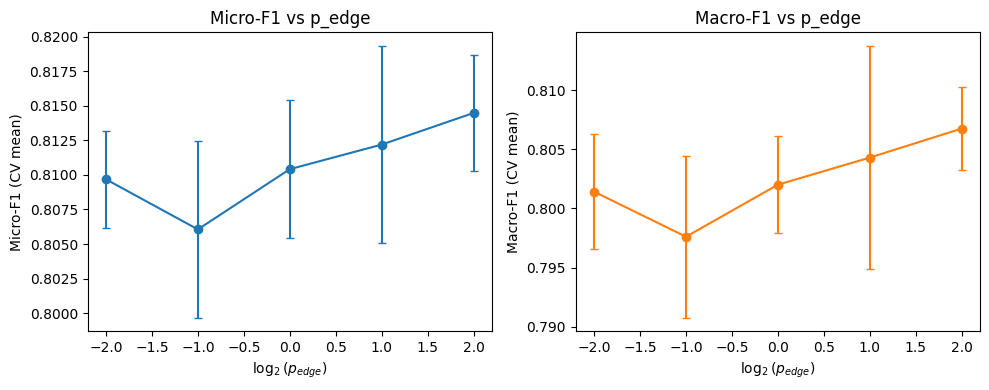

In [18]:
# Plot p_edge sweep
curve_pedge = results_pedge.sort_values("p_edge")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
x = np.log2(curve_pedge["p_edge"].to_numpy())

axes[0].errorbar(x, curve_pedge["micro_f1_mean"], yerr=curve_pedge["micro_f1_std"], marker="o", capsize=3)
axes[0].set_xlabel(r"$\log_2(p_{edge})$")
axes[0].set_ylabel("Micro-F1 (CV mean)")
axes[0].set_title("Micro-F1 vs p_edge")

axes[1].errorbar(x, curve_pedge["macro_f1_mean"], yerr=curve_pedge["macro_f1_std"], marker="o", capsize=3, color="tab:orange")
axes[1].set_xlabel(r"$\log_2(p_{edge})$")
axes[1].set_ylabel("Macro-F1 (CV mean)")
axes[1].set_title("Macro-F1 vs p_edge")

fig.tight_layout()
plt.show()

## Joint plot: `q_edge` and `p_edge` sweeps (2x2)

This compares both sweeps in one figure with four subplots:
- top row: `q_edge` (Micro, Macro)
- bottom row: `p_edge` (Micro, Macro)

It expects `results` (q-edge) and `results_pedge` (p-edge) to already be available.

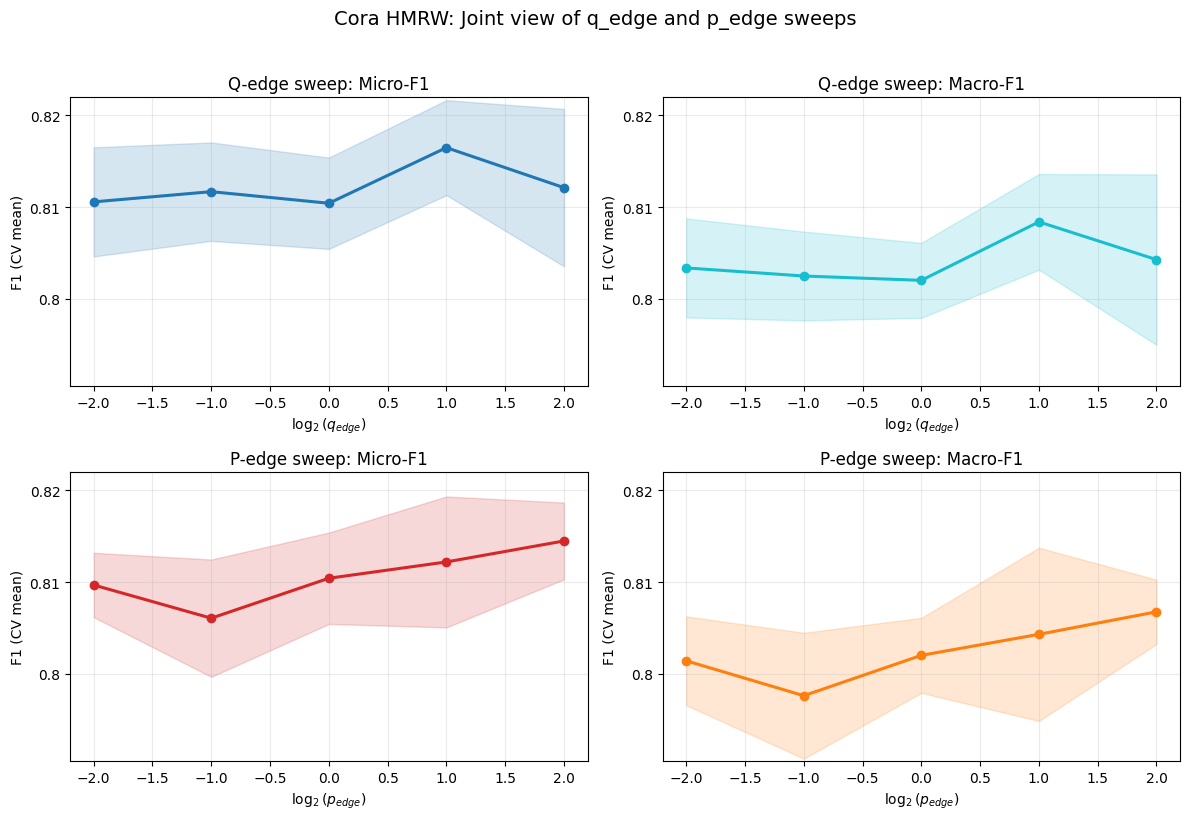

In [22]:
# 2x2 joint plot with improved colors
q_curve = results.sort_values("q_edge")
p_curve = results_pedge.sort_values("p_edge")

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False)

# Colors chosen for contrast and readability
c_q_micro = "#1f77b4"   # blue
c_q_macro = "#17becf"   # cyan
c_p_micro = "#d62728"   # red
c_p_macro = "#ff7f0e"   # orange

def plot_with_band(ax, x, y, yerr, color, title, xlabel):
    ax.plot(x, y, marker="o", linewidth=2.2, markersize=6, color=color)
    ax.fill_between(x, y - yerr, y + yerr, color=color, alpha=0.18)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("F1 (CV mean)")
    ax.grid(alpha=0.25)

xq = np.log2(q_curve["q_edge"].to_numpy())
plot_with_band(
    axes[0, 0],
    xq,
    q_curve["micro_f1_mean"].to_numpy(),
    q_curve["micro_f1_std"].to_numpy(),
    c_q_micro,
    "Q-edge sweep: Micro-F1",
    r"$\log_2(q_{edge})$",
)
plot_with_band(
    axes[0, 1],
    xq,
    q_curve["macro_f1_mean"].to_numpy(),
    q_curve["macro_f1_std"].to_numpy(),
    c_q_macro,
    "Q-edge sweep: Macro-F1",
    r"$\log_2(q_{edge})$",
)

xp = np.log2(p_curve["p_edge"].to_numpy())
plot_with_band(
    axes[1, 0],
    xp,
    p_curve["micro_f1_mean"].to_numpy(),
    p_curve["micro_f1_std"].to_numpy(),
    c_p_micro,
    "P-edge sweep: Micro-F1",
    r"$\log_2(p_{edge})$",
)
plot_with_band(
    axes[1, 1],
    xp,
    p_curve["macro_f1_mean"].to_numpy(),
    p_curve["macro_f1_std"].to_numpy(),
    c_p_macro,
    "P-edge sweep: Macro-F1",
    r"$\log_2(p_{edge})$",
)

# Force the same y-axis range on all panels
all_lower = np.concatenate([
    q_curve["micro_f1_mean"].to_numpy() - q_curve["micro_f1_std"].to_numpy(),
    q_curve["macro_f1_mean"].to_numpy() - q_curve["macro_f1_std"].to_numpy(),
    p_curve["micro_f1_mean"].to_numpy() - p_curve["micro_f1_std"].to_numpy(),
    p_curve["macro_f1_mean"].to_numpy() - p_curve["macro_f1_std"].to_numpy(),
])
all_upper = np.concatenate([
    q_curve["micro_f1_mean"].to_numpy() + q_curve["micro_f1_std"].to_numpy(),
    q_curve["macro_f1_mean"].to_numpy() + q_curve["macro_f1_std"].to_numpy(),
    p_curve["micro_f1_mean"].to_numpy() + p_curve["micro_f1_std"].to_numpy(),
    p_curve["macro_f1_mean"].to_numpy() + p_curve["macro_f1_std"].to_numpy(),
])
ymin = float(all_lower.min())
ymax = float(all_upper.max())
pad = 0.01 * (ymax - ymin if ymax > ymin else 1.0)
from matplotlib.ticker import MultipleLocator, FuncFormatter

for ax in axes.ravel():
    ax.set_ylim(ymin - pad, ymax + pad)
    ax.yaxis.set_major_locator(MultipleLocator(0.01))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.2f}".rstrip("0").rstrip(".")))

fig.suptitle("Cora HMRW: Joint view of q_edge and p_edge sweeps", fontsize=14, y=1.02)
fig.tight_layout()
plt.show()

## Grid sweep: `p_edge` × `q_edge`

This section evaluates combinations of `p_edge` and `q_edge` on Cora.

- x-axis: `p_edge`
- y-axis: `q_edge`
- metrics: Micro-F1 and Macro-F1
- repeated runs per setting to estimate mean and std

In [ ]:
# Run full (p_edge, q_edge) grid
pq_fixed_params = dict(
    p=1.0,
    q=1.0,
    num_walks=10,
    walk_length=40,
    window=10,
    dim=128,
    workers=1,
)

p_edge_grid = [0.25, 0.5, 1.0, 2.0, 4.0]
q_edge_grid = [0.25, 0.5, 1.0, 2.0, 4.0]
n_repeats_pq = 5
base_seed_pq = 42

rows_pq = []
for p_edge in p_edge_grid:
    for q_edge in q_edge_grid:
        print(f"p_edge={p_edge}, q_edge={q_edge}")
        micro_runs, macro_runs = [], []
        for rep in range(n_repeats_pq):
            seed = base_seed_pq + rep
            X = hmrw_embeddings(H, p_edge=p_edge, q_edge=q_edge, seed=seed, **pq_fixed_params)
            micro, macro = evaluate_embeddings(X, y, seed=seed)
            micro_runs.append(micro)
            macro_runs.append(macro)

        rows_pq.append(
            {
                "p_edge": p_edge,
                "q_edge": q_edge,
                "micro_f1_mean": float(np.mean(micro_runs)),
                "micro_f1_std": float(np.std(micro_runs)),
                "micro_f1_var": float(np.var(micro_runs)),
                "macro_f1_mean": float(np.mean(macro_runs)),
                "macro_f1_std": float(np.std(macro_runs)),
                "macro_f1_var": float(np.var(macro_runs)),
            }
        )

results_pq = pd.DataFrame(rows_pq).sort_values(["macro_f1_mean", "micro_f1_mean"], ascending=False)

results_dir = Path("results") / "cora"
results_dir.mkdir(parents=True, exist_ok=True)
results_pq_path = results_dir / "hmrw_pedge_qedge_grid.csv"
results_pq.to_csv(results_pq_path, index=False)
print(f"Saved grid results to: {results_pq_path}")

results_pq.head(10)

In [ ]:
# Bubble plots: color = mean score, marker size = variance
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

# Scale variances for visible bubble sizes
size_micro = 12000 * (results_pq["micro_f1_var"].to_numpy() + 1e-6)
size_macro = 12000 * (results_pq["macro_f1_var"].to_numpy() + 1e-6)

sc0 = axes[0].scatter(
    results_pq["p_edge"],
    results_pq["q_edge"],
    c=results_pq["micro_f1_mean"],
    s=size_micro,
    cmap="viridis",
    alpha=0.8,
    edgecolor="black",
    linewidth=0.5,
)
axes[0].set_title("Micro-F1: color=mean, size=variance")
axes[0].set_xlabel("p_edge")
axes[0].set_ylabel("q_edge")
axes[0].set_xscale("log", base=2)
axes[0].set_yscale("log", base=2)
axes[0].set_xticks(p_edge_grid, [str(v) for v in p_edge_grid])
axes[0].set_yticks(q_edge_grid, [str(v) for v in q_edge_grid])
axes[0].grid(alpha=0.2)
fig.colorbar(sc0, ax=axes[0], fraction=0.046, label="Micro-F1 mean")

sc1 = axes[1].scatter(
    results_pq["p_edge"],
    results_pq["q_edge"],
    c=results_pq["macro_f1_mean"],
    s=size_macro,
    cmap="magma",
    alpha=0.8,
    edgecolor="black",
    linewidth=0.5,
)
axes[1].set_title("Macro-F1: color=mean, size=variance")
axes[1].set_xlabel("p_edge")
axes[1].set_xscale("log", base=2)
axes[1].set_yscale("log", base=2)
axes[1].set_xticks(p_edge_grid, [str(v) for v in p_edge_grid])
axes[1].set_yticks(q_edge_grid, [str(v) for v in q_edge_grid])
axes[1].grid(alpha=0.2)
fig.colorbar(sc1, ax=axes[1], fraction=0.046, label="Macro-F1 mean")

fig.suptitle("Cora HMRW grid sweep: bubble plots", y=1.03)
fig.tight_layout()
plt.show()

In [ ]:
# Heatmaps: mean and std for Micro/Macro-F1
micro_mean = results_pq.pivot(index="q_edge", columns="p_edge", values="micro_f1_mean").sort_index().sort_index(axis=1)
micro_std = results_pq.pivot(index="q_edge", columns="p_edge", values="micro_f1_std").sort_index().sort_index(axis=1)
macro_mean = results_pq.pivot(index="q_edge", columns="p_edge", values="macro_f1_mean").sort_index().sort_index(axis=1)
macro_std = results_pq.pivot(index="q_edge", columns="p_edge", values="macro_f1_std").sort_index().sort_index(axis=1)

fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)

im00 = axes[0, 0].imshow(micro_mean.values, aspect="auto", cmap="viridis")
axes[0, 0].set_title("Micro-F1 mean")
fig.colorbar(im00, ax=axes[0, 0], fraction=0.046)

im01 = axes[0, 1].imshow(micro_std.values, aspect="auto", cmap="Blues")
axes[0, 1].set_title("Micro-F1 std")
fig.colorbar(im01, ax=axes[0, 1], fraction=0.046)

im10 = axes[1, 0].imshow(macro_mean.values, aspect="auto", cmap="magma")
axes[1, 0].set_title("Macro-F1 mean")
fig.colorbar(im10, ax=axes[1, 0], fraction=0.046)

im11 = axes[1, 1].imshow(macro_std.values, aspect="auto", cmap="Oranges")
axes[1, 1].set_title("Macro-F1 std")
fig.colorbar(im11, ax=axes[1, 1], fraction=0.046)

for ax in axes.ravel():
    ax.set_xlabel("p_edge")
    ax.set_ylabel("q_edge")
    ax.set_xticks(range(len(micro_mean.columns)), [str(v) for v in micro_mean.columns])
    ax.set_yticks(range(len(micro_mean.index)), [str(v) for v in micro_mean.index])

fig.suptitle("Cora HMRW grid sweep: heatmaps", y=1.01)
fig.tight_layout()
plt.show()